In [13]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
import os
from pydantic import BaseModel, Field
import operator

In [8]:
load_dotenv()  # Load environment variables from .env file

model = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash",
    api_key=os.getenv("API_KEY"),
    temperature=0)


In [7]:
class EvaluationSchema(BaseModel):
    score: int = Field(..., description="Score from 1 to 10", ge=0, le=10)
    feedback: str = Field(..., description="Feedback on the essay")

In [10]:
structured_model = model.with_structured_output(EvaluationSchema)

In [11]:
essay= """Global warming refers to the steady increase in Earth’s average surface temperature, driven primarily by human activities like burning fossil fuels and deforestation. These actions trap greenhouse gases in the atmosphere, accelerating glacier melt, extreme weather, and rising sea levels. Transitioning to clean energy and protecting forests are crucial steps to safeguard our planet’s future."""
prompt = f"Evaluate the following essay and provide a score from 1 to 10 along with feedback:\n\n{essay}"

In [12]:
structured_model.invoke(prompt)

d:\Tutorials\SimpleChatBot\venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


EvaluationSchema(score=8, feedback='The essay provides a clear, concise, and accurate overview of global warming, covering its causes, consequences, and solutions. To improve, the essay could be expanded with specific examples, data, or elaboration on particular mitigation strategies.')

In [16]:
class EssayEvaluation(TypedDict):
    essay: str
    language_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    individual_scores: Annotated[list[int], operator.add] # Reducer for keeping multiple values updated into list at parallel time
    avg_score: float

In [26]:
def llm_language_evalucation(state: EssayEvaluation) -> dict:
    essay = state["essay"]
    prompt = f"Evaluate the following essay on the basis of language quality and provide a score from 1 to 10 along with feedback:\n\n{essay}"
    result = structured_model.invoke(prompt)
    return{"language_feedback": result.feedback, "individual_scores": [result.score]}

def llm_analysis_evaluation(state: EssayEvaluation) -> dict:
    essay = state["essay"]
    prompt = f"Evaluate the following essay on the basis of depth of analysis and provide a score from 1 to 10 along with feedback:\n\n{essay}"
    result = structured_model.invoke(prompt)
    return{"analysis_feedback": result.feedback, "individual_scores": [result.score]}

def llm_thought_evaluation(state: EssayEvaluation) -> dict:
    essay = state["essay"]
    prompt = f"Evaluate the following essay on the basis of clarity of thought and provide a score from 1 to 10 along with feedback:\n\n{essay}"
    result = structured_model.invoke(prompt)
    return{"clarity_feedback": result.feedback, "individual_scores": [result.score]}

def llm_final_evaluation(state: EssayEvaluation) -> dict:
    essay = state["essay"]
    summary_feedback = f"Based on the following feedback create summarize feedback \n language feedback: {state['language_feedback']}\n analysis feedback: {state['analysis_feedback']}\n clarity feedback: {state['clarity_feedback']}"
    final_summary = model.invoke(summary_feedback).text

    avg_score = sum(state["individual_scores"]) / len(state["individual_scores"])
    return{"overall_feedback": final_summary, "avg_score": avg_score}

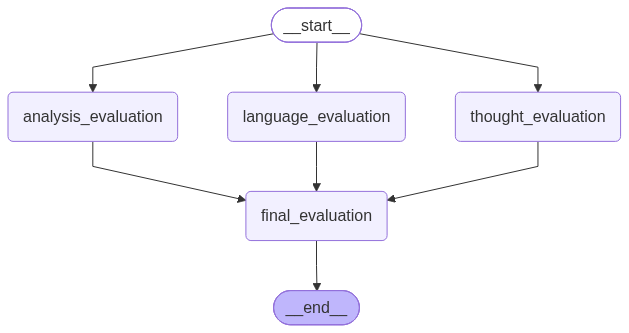

In [24]:
graph = StateGraph(EssayEvaluation)

graph.add_node("language_evaluation", llm_language_evalucation)
graph.add_node("analysis_evaluation", llm_analysis_evaluation)
graph.add_node("thought_evaluation", llm_thought_evaluation)
graph.add_node("final_evaluation", llm_final_evaluation)

graph.add_edge(START, "language_evaluation")
graph.add_edge(START, "analysis_evaluation")
graph.add_edge(START, "thought_evaluation")
graph.add_edge("language_evaluation", "final_evaluation")
graph.add_edge("analysis_evaluation", "final_evaluation")
graph.add_edge("thought_evaluation", "final_evaluation")
graph.add_edge("final_evaluation", END)

workflow = graph.compile()

workflow

In [25]:
initial_state = {"essay":"Global warming refers to the steady increase in Earth’s average surface temperature, driven primarily by human activities like burning fossil fuels and deforestation. These actions trap greenhouse gases in the atmosphere, accelerating glacier melt, extreme weather, and rising sea levels. Transitioning to clean energy and protecting forests are crucial steps to safeguard our planet’s future."}
workflow.invoke(initial_state)

d:\Tutorials\SimpleChatBot\venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\Tutorials\SimpleChatBot\venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\Tutorials\SimpleChatBot\venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\Tutorials\SimpleChatBot\venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = 

{'essay': 'Global warming refers to the steady increase in Earth’s average surface temperature, driven primarily by human activities like burning fossil fuels and deforestation. These actions trap greenhouse gases in the atmosphere, accelerating glacier melt, extreme weather, and rising sea levels. Transitioning to clean energy and protecting forests are crucial steps to safeguard our planet’s future.',
 'language_feedback': 'The essay demonstrates excellent language quality, concise phrasing, precise vocabulary, and correct grammar and punctuation.',
 'analysis_feedback': 'The essay provides a clear and concise overview of global warming, covering its causes, effects, and basic solutions. However, it lacks depth of analysis. To improve, it should explore the specific mechanisms behind greenhouse gas effects, provide supporting data or examples, and analyze the economic or social complexities of transitioning to clean energy.',
 'clarity_feedback': 'The essay demonstrates exceptional c